# Individuell uppgift – Hälsostudie

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from scipy import stats
from sklearn.linear_model import LinearRegression
np.random.seed(42)

df = pd.read_csv("data/health_study_dataset.csv")

print(df.isna().sum())
print()
print(df.duplicated().sum())
print()
print(df.dtypes)
df.head()

# Can't find anything wrong with the csv file so no cleaning needed

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

0

id               int64
age              int64
sex                str
height         float64
weight         float64
systolic_bp    float64
cholesterol    float64
smoker             str
disease          int64
dtype: object


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [2]:
# calcluates the different values of columns
cols = ["age", "weight", "height", "systolic_bp", "cholesterol"]

df[cols].agg(["mean", "median", "min", "max"]).T.round(2)


,mean,median,min,max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


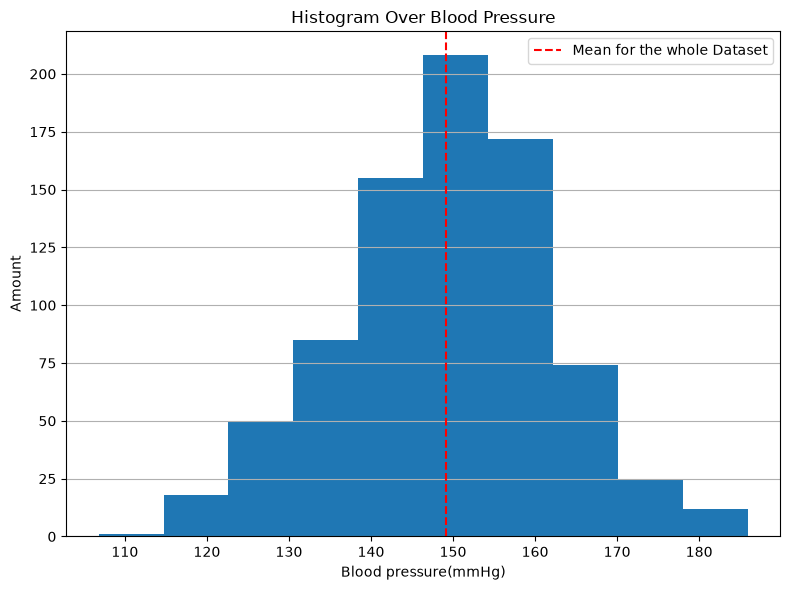

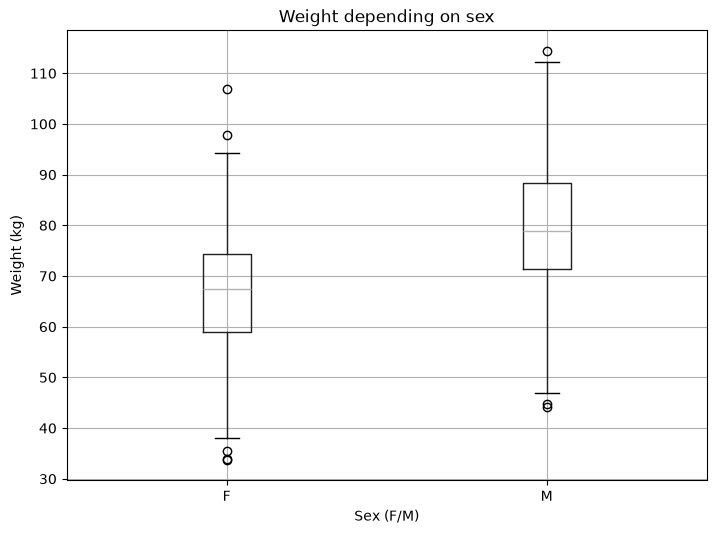

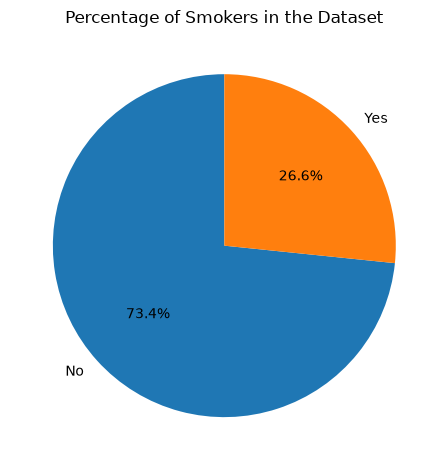

In [3]:
fig, ax = plt.subplots(figsize=(8,6))
ax.hist(df["systolic_bp"])
ax.axvline(df["systolic_bp"].mean(), color="red", linestyle="--", label="Mean for the whole Dataset")
ax.set_title("Histogram Over Blood Pressure")
ax.set_xlabel("Blood pressure(mmHg)")
ax.set_ylabel("Amount")
ax.grid(True, axis="y")
ax.legend()
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(8,6))
df.boxplot(column="weight", by="sex", ax=ax)
plt.suptitle("")
ax.set_title("Weight depending on sex")
ax.set_xlabel("Sex (F/M)")
ax.set_ylabel("Weight (kg)")
plt.show()


share_smokers = df["smoker"].value_counts(normalize=True) * 100

fig, ax = plt.subplots()
ax.pie(
    share_smokers.values,
    labels=share_smokers.index,
    autopct="%1.1f%%",
    startangle=90,
)
ax.set_title("Percentage of Smokers in the Dataset")
plt.tight_layout()
plt.show()

In [4]:
# share in %
share_disease = df["disease"].mean() * 100

print(f"The share of people with the disease from the dataset is: {share_disease:.1f} % ")
print()

# check to see if data matches
amount_disease = (df["disease"] == 1).sum()
total_people = len(df)
print(amount_disease, total_people) 



The share of people with the disease from the dataset is: 5.9 % 

47 800


In [5]:
p = df["disease"].mean()
sim_disease = np.random.binomial(n=1, p=p, size=1000)
sim_share = sim_disease.mean() * 100
diff =  sim_share - share_disease


print(f"Prevalence of disease in dataset: {share_disease:.1f} %")
print(f"Prevalence of disease in simulation: {sim_share:.1f} %")
print(f"Difference between simulation and in dataset: {diff:.1f} (percentage points)")

Prevalence of disease in dataset: 5.9 %
Prevalence of disease in simulation: 5.6 %
Difference between simulation and in dataset: -0.3 (percentage points)


In [6]:
systolic = df["systolic_bp"]

n = len(systolic)
m = systolic.mean()
s = systolic.std(ddof=1)
se = s/ np.sqrt(len(systolic))
z = 1.96

lower = m - z*se
upper = m + z*se

print("Size of the sample:", n)
print("Point estimate (mean):", m)
print("Sample standard deviation:", s)
print("Standard error:", se)
print(f"95% CI: ({lower:.2f}, {upper:.2f})")

Size of the sample: 800
Point estimate (mean): 149.178625
Sample standard deviation: 12.793360316766597
Standard error: 0.4523135917074269
95% CI: (148.29, 150.07)


In [7]:
# Significance level: Alpha = 0.05

smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"]
non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"]

t_stat_w, p_val_w = stats.ttest_ind(smokers, non_smokers, equal_var=False, alternative="greater")

print(f"Welch t-test: t = {t_stat_w:.3f}, p = {p_val_w:.4f}")


Welch t-test: t = 0.450, p = 0.3264


- The test statistic is 0.450, which is fairly small and not unusual.
- The p-value is 0.3264, which is > alpha. Therefore we fail to reject H0
- We do not have sufficient evidence that smokers have a higher mean blood pressure than non-smokers.

In [8]:
def ci_normal(data, z=1.96):
    """
    Function that calculates the CI, 
    Returns the lower and upper confidence interval for the mean
    z is 1.96 and corresponds to 95% ,data is a pandas Series
    """
    m = data.mean()
    s = data.std(ddof=1)
    se = s/ np.sqrt(len(data))
    lower = m - z*se
    upper = m + z*se
    return lower, upper

# Test for the function
lower, upper = ci_normal(df["systolic_bp"])
print(f"95% CI: ({lower:.2f}, {upper:.2f})")


def welch_test(smokers, non_smokers, alternative="greater"):
    """
    Function that calculates a welch test
    smokers, non_smokers: pandas Series with blood pressure values
    alternative: "greater" tests if the mean of the first group is larger.
    Returns the t statistic and the p-value.
    """
    t_stat,  p_val = stats.ttest_ind(smokers, non_smokers, equal_var=False, alternative=alternative)

    return t_stat, p_val


# Test for the function 
t_stat, p_val =  welch_test(smokers, non_smokers, alternative="less")
print(t_stat, p_val)




95% CI: (148.29, 150.07)
0.4503433193393224 0.6736330628300502


- Skapade funktioner för ett konfidensintervall för medelvärdet med normalapproximation och ett welch test. 
- Att göra dem till funktioner gör det lättare att återanvända på andra kolumner eller grupper utan att koden behöver kopieras, samt att koden blir dokumenterad med docstrings
- Jag valde Welch-test (equal_var=False) eftersom det inte antar lika varians i grupperna, vilket ger säkrare p-värden när spridningen skiljer sig, särskilt när grupperna är olika stora.

               mean  median    min     max
age           49.43   50.00   18.0   90.00
weight        73.41   73.20   33.7  114.40
height       171.85  171.35  144.4  200.40
systolic_bp  149.18  149.40  106.8  185.90
cholesterol    4.93    4.97    2.5    7.88


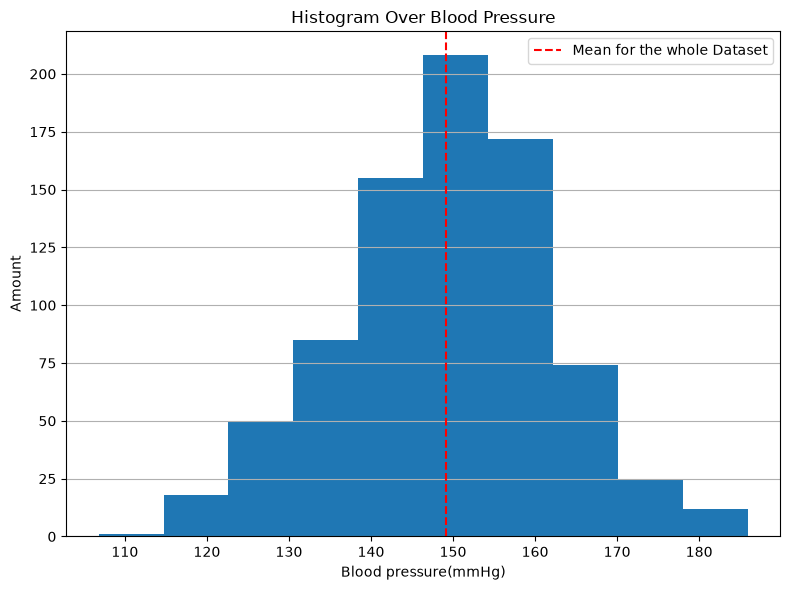

[122.6848897   0.5360256]


In [9]:
class HealthAnalyzer:
    """ Collects, organizes, and summarizes health data analyses. """

    def __init__(self, df):
        self.df = df.copy()

    def summary_stats(self):
        """ Calculates basic statistics (mean, median, min, max) for the numeric columns. """
      
        cols = ["age", "weight", "height", "systolic_bp", "cholesterol"]
        return self.df[cols].agg(["mean", "median", "min", "max"]).T.round(2)

    def plot_bp_histogram(self):
        """ Plots a histogram of systolic blood pressure. """

        fig, ax = plt.subplots(figsize=(8,6))
        ax.hist(self.df["systolic_bp"])
        ax.axvline(self.df["systolic_bp"].mean(), color="red", linestyle="--", label="Mean for the whole Dataset")
        ax.set_title("Histogram Over Blood Pressure")
        ax.set_xlabel("Blood pressure(mmHg)")
        ax.set_ylabel("Amount")
        ax.grid(True, axis="y")
        ax.legend()
        plt.tight_layout()
        plt.show()

    def fit_regression(self):
        """ A regression calculating the connection between blood pressure and age
           Returns x, y and the coefficients (intercept and slope). 
        """

        x = self.df[["age"]].to_numpy()
        y = self.df["systolic_bp"].to_numpy()
        ones = np.ones(len(x))
        X = np.column_stack((ones, x))
        beta_hat = np.linalg.inv(X.T @ X) @ X.T @ y
        return x, y, beta_hat


analyzer = HealthAnalyzer(df)
print(analyzer.summary_stats())
analyzer.plot_bp_histogram()
x, y, beta_hat = analyzer.fit_regression()
print(beta_hat)


- Klassen är skapad eftersom datan sparas bara en gång och delas av alla metoder
- Valde att arbeta i en "df.copy()" med klassen för att inte påverka datan i den ursprungliga DataFramen
- Använde matrislösningen (normalekvationerna X.T @ X) eftersom den hittar linjen som minimerar summan av de kvadrerade avstånden mellan punkterna och linjen.
- Körde "LinearRegression" och fick samma tal som med min lösning, vilket visar att det stämmer.

In [10]:
x = df[["age"]].to_numpy()
y = df["systolic_bp"].to_numpy()
ones = np.ones(len(x))
X = np.column_stack((ones, x))
beta_hat = np.linalg.inv(X.T @ X) @ X.T @ y
model = LinearRegression()
model.fit(x, y)

model_intercept = float(model.intercept_)
model_slope = float(model.coef_[0])
model_r2 = float(model.score(x, y))

print(beta_hat)
print(model_intercept, model_slope)
print(f"R² = {model_r2:.3f}")


[122.6848897   0.5360256]
122.68488970435858 0.5360255996690306
R² = 0.369


- The slope shows that for each additional year the BP (mmHg) rises by 0.54 mmHg
- The intercept (122.68) is the value of the BP when the age is 0, in other words the starting point.  
Note that the youngest person in this data is at the age of 18, so do not interpret the the intercept literally.
- Age can explain around 37% of the variation in blood pressure, the value is moderate, it is not enough on its own to predict the value.

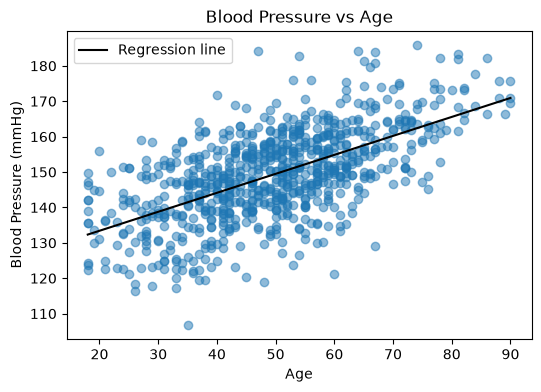

In [11]:
x_line = np.linspace(x.min(), x.max())
y_line = model_intercept + model_slope * x_line

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x, y, alpha=0.5)     
ax.plot(x_line, y_line, color="black", label="Regression line")
ax.set_title("Blood Pressure vs Age")
ax.set_xlabel("Age")
ax.set_ylabel("Blood Pressure (mmHg)")
ax.legend()
plt.show()

- The graph shows a clear connection between higher blood pressure and higher age, it shows that the higher your age is the higher your blood pressure is on average
- Most of the dots are centered around the line like a cloud, with some deviations, this is in line with R² = 0.369, since the dots spread out from the line
- Even if there's a clear connection between age and blood pressure, age alone still doesn't dictate your blood pressure